In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../vacancies_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (1351, 20)

Columns:
['Vakansiya adı', 'Şirkət', 'Link', 'city', 'category', 'salary', 'job_type', 'education', 'deadline', 'description', 'title', 'experience', 'error', 'age', 'job_title', 'is_premium', 'skills', 'exp_years', 'seniority', 'job_group']


,Vakansiya adı,Şirkət,Link,city,category,salary,job_type,education,deadline,description,title,experience,error,age,job_title,is_premium,skills,exp_years,seniority,job_group
0,Memar-dizayner\n\nPREMİUM,PREMİUM,https://www.hellojob.az/vakansiya/memar-dizayn...,"Bakı, Çinar Park Biznes Mərkəzi",Memar / İnteryer dizaynı,800 - 1000 AZN,Tam-ştat,Bakalavr,31 oktyabr 2026,Memar-dizayner Ana səhifə Vakansiyalar Dizayn ...,Memar-dizayner,NaN,NaN,NaN,Memar-dizayner,True,"sap, autocad, satış",NaN,NaN,Marketinq
1,Xadimə\n\nPREMİUM,PREMİUM,https://www.hellojob.az/vakansiya/xadime-16564596,"Bakı, Xətai pr. 142",Xadimə,500 AZN,Tam-ştat,Vacib deyil,30 oktyabr 2026,Xadimə Ana səhifə Vakansiyalar Xidmət Xadimə X...,Xadimə,NaN,NaN,NaN,Xadimə,True,sap,NaN,NaN,Xidmət
2,Satış koordinatoru\n\nPREMİUM,PREMİUM,https://www.hellojob.az/vakansiya/satis-koordi...,Bakı,Satış üzrə mütəxəssis,Razılaşma ilə,Tam-ştat,Bakalavr,11 oktyabr 2026,Satış koordinatoru Ana səhifə Vakansiyalar Sat...,Satış koordinatoru,NaN,NaN,NaN,Satış koordinatoru,True,"sap, satış",NaN,NaN,Satış
3,Nəzarətçi\n\nPREMİUM,PREMİUM,https://www.hellojob.az/vakansiya/nezaretci-16...,"Bakı, HƏZİ ASLANOV,XUDU MƏMMƏDOV 145",Digər,600 AZN,Tam-ştat,Vacib deyil,31 oktyabr 2026,Nəzarətçi Ana səhifə Vakansiyalar Xidmət Digər...,Nəzarətçi,NaN,NaN,NaN,Nəzarətçi,True,"sap, ingilis dili, rus dili, satış, sürücülük",NaN,NaN,Digər
4,Köməkçi (Porter)\n\nPREMİUM,PREMİUM,https://www.hellojob.az/vakansiya/komekci-1659...,"Bakı, Mikayıl Müşfiq 2A",Tibbi personal,500 AZN,Tam-ştat,Vacib deyil,31 oktyabr 2026,Köməkçi (Porter) Ana səhifə Vakansiyalar Səhiy...,Köməkçi (Porter),NaN,NaN,NaN,Köməkçi (Porter),True,"sap, satış",NaN,NaN,Digər


In [2]:
print("Missing values:")
print(df.isna().sum())

print("\nJob group distribution:")
print(df["job_group"].value_counts())

print("\nJob group percentages:")
print(
    (df["job_group"].value_counts(normalize=True) * 100).round(2)
)

Missing values:
Vakansiya adı       0
Şirkət           1250
Link                0
city                0
category            0
salary              0
job_type          484
education         697
deadline            1
description         0
title               0
experience       1347
error            1351
age              1350
job_title           0
is_premium          0
skills              0
exp_years        1349
seniority        1349
job_group           0
dtype: int64

Job group distribution:
job_group
Digər        745
Satış        249
IT           189
Xidmət        62
Marketinq     55
Maliyyə       51
Name: count, dtype: int64

Job group percentages:
job_group
Digər        55.14
Satış        18.43
IT           13.99
Xidmət        4.59
Marketinq     4.07
Maliyyə       3.77
Name: proportion, dtype: float64


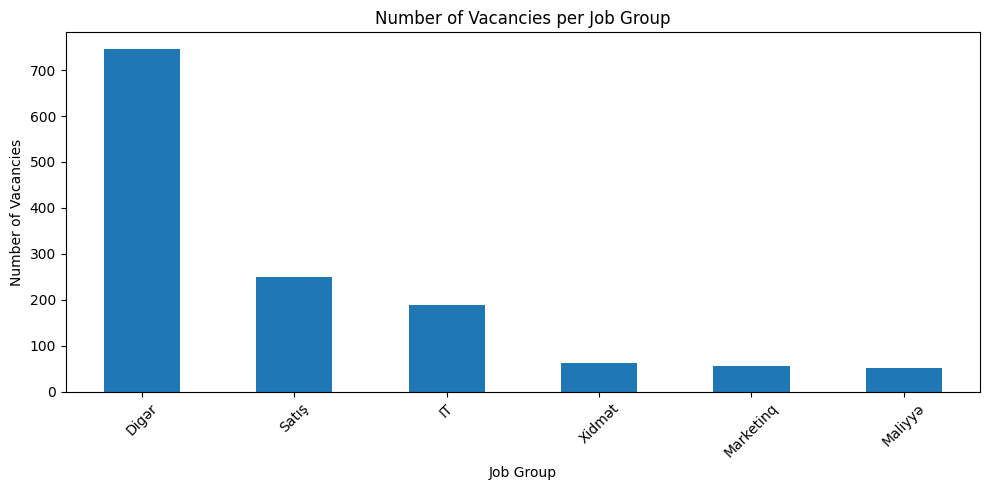

In [3]:
df["job_group"].value_counts().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Number of Vacancies per Job Group")
plt.xlabel("Job Group")
plt.ylabel("Number of Vacancies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
df["description"] = df["description"].fillna("").astype(str)

df["text_length"] = df["description"].str.len()

print(df["text_length"].describe())

print("\nSample job titles:")
print(df["job_title"].head(10))

print("\nSample skills:")
print(df["skills"].head(10))

count    1351.000000
mean     5918.073279
std        51.710288
min      5745.000000
25%      5884.000000
50%      5914.000000
75%      5962.000000
max      6000.000000
Name: text_length, dtype: float64

Sample job titles:
0                                  Memar-dizayner
1                                          Xadimə
2                              Satış koordinatoru
3                                       Nəzarətçi
4                                Köməkçi (Porter)
5                                         Müəllim
6                                          Kuryer
7    Müştəri dəstəyi və Təhlükəsizlik mütəxəssisi
8                            Call-Center Operator
9                          Tender üzrə mütəxəssis
Name: job_title, dtype: str

Sample skills:
0                                  sap, autocad, satış
1                                                  sap
2                                           sap, satış
3        sap, ingilis dili, rus dili, satış, sürücülük
4             

In [5]:
# 1. Original categories
print("Number of original categories:", df["category"].nunique())

print("\nOriginal category distribution:")
print(df["category"].value_counts().to_string())

# 2. Our generated job groups
print("\nGenerated job groups:")
print(df["job_group"].value_counts().to_string())

# 3. Compare original categories with generated groups
print("\nCategory vs Job Group:")
print(
    pd.crosstab(df["category"], df["job_group"]).to_string()
)

# 4. Inspect random examples
print("\nRandom examples:")
print(
    df[["job_title", "category", "skills", "job_group"]]
    .sample(30, random_state=42)
    .to_string(index=False)
)

Number of original categories: 65

Original category distribution:
category
Digər                             247
Satış üzrə mütəxəssis             152
Bank işi                          112
Bank xidməti                      103
Kredit mütəxəssisi                 81
Texnologiya                        72
Maliyyə                            49
Satış                              48
Proqramlaşdırma                    40
Təhsil                             35
Mühasibat                          29
Xüsusi təhsil/ Təlim               27
Marketinq                          25
SMM                                20
Operator                           19
Xadimə                             15
Hüquqşünas                         15
İnsan resursları                   15
Anbardar                           13
Rəqəmsal marketinq                 13
Sürücü                             13
İnzibati                           11
Turizm və mehmanxana işi           11
Maliyyə analiz                     11
Maaş        